# DataLab Cup 1: Predicting News Popularity — 報告

作者：潘昱翔 (Yu-Xiang Pan)

## 方法總覽

整個流程是把每篇 Mashable 新聞的原始 HTML 轉成特徵，再結合線性文字模型與梯度提升樹（gradient-boosted tree）模型：

1. **資料前處理**：用 BeautifulSoup 把網頁拆成標題、作者、發佈時間、頻道（channel）、主題（topics）、內文等欄位；文字轉小寫、移除 NLTK stop words，並做 Porter stemming。
2. **文字轉向量**：依照 tutorial 比較 BoW、TF-IDF 與 feature hashing，最後對每個欄位分別使用 TF-IDF（uni-gram 與 bi-gram）。
3. **特徵**：發佈的星期與時段、頻道、作者、主題；圖片、影片、連結數量；文章長度；標題風格；以及「時間脈絡」特徵（同時段發文量、前後幾天其他文章的熱門率）。
4. **分類器**：
   * 對每一組稀疏特徵各訓練一個 out-of-fold logistic regression。
   * 把這些預測值和 metadata、時間脈絡、topic encoding、SVD 等特徵一起交給一個 LightGBM（stacking），並平均 10 個 random seed。


## 0. 環境設定

In [1]:
import os, re, time, pickle, warnings
from pathlib import Path
from functools import lru_cache

import numpy as np
import pandas as pd
from scipy import sparse
from scipy.stats import rankdata
from bs4 import BeautifulSoup
from nltk.stem.porter import PorterStemmer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, HashingVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import roc_auc_score
import lightgbm as lgb
%matplotlib inline

warnings.filterwarnings('ignore')
SEED, N_FOLDS = 42, 5
RUN_BASELINES = True   # section 2 comparison (BoW / TF-IDF / Hashing); set False to save time

DATA_DIR = Path(os.environ.get('DATA_DIR', 'data'))
if not (DATA_DIR / 'train.csv').exists():
    DATA_DIR = Path('.')
assert (DATA_DIR / 'train.csv').exists(), 'Put train.csv / test.csv in ./data or next to this notebook'
CACHE = DATA_DIR / 'parsed_cache.pkl'

train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
y = (train['Popularity'] == 1).astype(int).values
print(train.shape, test.shape)
print(train['Popularity'].value_counts())
train.head()

(27643, 3) (11847, 2)
Popularity
-1    14011
 1    13632
Name: count, dtype: int64


,Id,Popularity,Page content
0,0,-1,"<html><head><div class=""article-info""> <span c..."
1,1,1,"<html><head><div class=""article-info""><span cl..."
2,2,1,"<html><head><div class=""article-info""><span cl..."
3,3,-1,"<html><head><div class=""article-info""><span cl..."
4,4,-1,"<html><head><div class=""article-info""><span cl..."


## 1. 資料前處理

### 1.1 HTML 解析：選取特定標籤

Tutorial 用 `get_text()` 把所有 HTML 標籤移除。但新聞網頁比影評的結構複雜得多，不同標籤帶有不同種類的資訊，所以不把整頁壓平成一串文字，而是分別抽出每個欄位：

| 欄位 | 來源標籤 |
|---|---|
| 標題 | `<h1 class="title">` |
| 作者 | `<span class="author_name">` / byline |
| 來源媒體（publisher） | byline 中的 `<a href="/publishers/...">`（例如 Space.com 等轉載文章；沒有的話就是 Mashable） |
| 發佈時間 | `<time datetime=...>` |
| 頻道（channel） | `<article data-channel=...>` |
| 主題（topics） | `<footer class="article-topics">` 中的 `<a>` |
| 內文 | `<section class="article-content">` |

也從內文計算結構元素的數量（圖片、影片、連結、段落、嵌入推文等），並記錄標題的風格：長度、有沒有 `?` 或 `!`、有沒有數字、大寫比例。

In [2]:
def text_of(tag):
    return tag.get_text(' ', strip=True) if tag is not None else ''

def parse_article(html):
    soup = BeautifulSoup(html, 'lxml')
    title = text_of(soup.find('h1'))
    author = text_of(soup.find(class_='author_name') or soup.find(class_='byline'))
    author = re.sub(r'^\s*by\s+', '', author, flags=re.I).strip().lower() or 'unknown'
    info = soup.find(class_='article-info') or soup
    pub = info.find('a', href=re.compile(r'/publishers/'))
    publisher = pub['href'].strip('/').split('/')[-1] if pub is not None else 'mashable'
    t = soup.find('time')
    article = soup.find('article')
    channel = (article.get('data-channel') if article is not None else None) or 'unknown'
    footer = soup.find('footer')
    topics = [a.get_text(strip=True).lower() for a in footer.find_all('a')] if footer is not None else []
    body = soup.find('section', class_='article-content') or soup.find('body') or soup
    content = body.get_text(' ', strip=True)
    words = content.split()
    title_words = title.split()
    return dict(
        title=title, author=author, channel=channel.strip().lower(), publisher=publisher,
        has_author_image=int(info.find(class_='author_image') is not None),
        has_author_geo=int(info.find(class_='author_geo') is not None),
        datetime=t.get('datetime') if t is not None else None,
        topics='|'.join(topics), content=content,
        # body structure
        n_words=len(words),
        n_unique_words=len({w.lower() for w in words}),
        n_chars=len(content),
        avg_word_len=np.mean([len(w) for w in words]) if words else 0.0,
        n_paragraphs=len(body.find_all('p')),
        n_links=len(body.find_all('a')),
        n_images=len(body.find_all('img')),
        n_videos=len(body.find_all(['iframe', 'video'])),
        n_blockquotes=len(body.find_all('blockquote')),
        n_lists=len(body.find_all(['ul', 'ol'])),
        n_bold=len(body.find_all(['strong', 'b'])),
        n_headings=len(body.find_all(['h2', 'h3', 'h4'])),
        n_figures=len(soup.find_all('figure')),
        n_topics=len(topics),
        n_question=content.count('?'),
        n_exclaim=content.count('!'),
        # title style
        title_n_words=len(title_words),
        title_n_chars=len(title),
        title_has_question=int('?' in title),
        title_has_exclaim=int('!' in title),
        title_has_colon=int(':' in title),
        title_has_digit=int(bool(re.search(r'\d', title))),
        title_upper_ratio=sum(w[:1].isupper() for w in title_words) / max(len(title_words), 1),
    )

if CACHE.exists():
    parsed_tr, parsed_te = pickle.load(open(CACHE, 'rb'))
else:
    t0 = time.time()
    parsed_tr = pd.DataFrame([parse_article(h) for h in train['Page content']])
    parsed_te = pd.DataFrame([parse_article(h) for h in test['Page content']])
    pickle.dump((parsed_tr, parsed_te), open(CACHE, 'wb'))
    print(f'parsed in {time.time() - t0:.0f}s')

parsed_tr[['title', 'author', 'publisher', 'channel', 'datetime', 'topics', 'n_words', 'n_images']].head()

,title,author,publisher,channel,datetime,topics,n_words,n_images
0,NASA's Grand Challenge: Stop Asteroids From De...,clara moskowitz,space-com,world,"Wed, 19 Jun 2013 15:04:30 +0000",asteroid|asteroids|challenge|earth|space|u.s.|...,592,0
1,Google's New Open Source Patent Pledge: We Won...,christina warren,mashable,tech,"Thu, 28 Mar 2013 17:40:55 +0000",apps and software|google|open source|opn pledg...,308,0
2,Ballin': 2014 NFL Draft Picks Get to Choose Th...,sam laird,mashable,entertainment,"Wed, 07 May 2014 19:15:20 +0000",entertainment|nfl|nfl draft|sports|television,1114,0
3,Cameraperson Fails Deliver Slapstick Laughs,sam laird,mashable,watercooler,"Fri, 11 Oct 2013 02:26:50 +0000",sports|video|videos|watercooler,279,0
4,NFL Star Helps Young Fan Prove Friendship With...,connor finnegan,mashable,entertainment,"Thu, 17 Apr 2014 03:31:43 +0000",entertainment|instagram|instagram video|nfl|sp...,1370,50


### 1.2 時間特徵

Tutorial 提示發佈的星期幾可能有影響。我把 `<time datetime>` 解析成年、月、星期、小時、是否週末，以及一個絕對時間指標（`days`），用來捕捉網站長期的趨勢變化。

In [3]:
def time_features(df):
    dt = pd.to_datetime(df['datetime'], utc=True, errors='coerce', format='mixed')
    out = pd.DataFrame(index=df.index)
    out['year'] = dt.dt.year
    out['month'] = dt.dt.month
    out['weekday'] = dt.dt.weekday
    out['hour'] = dt.dt.hour
    out['is_weekend'] = (dt.dt.weekday >= 5).astype(float).where(dt.notna())
    out['days'] = (dt - pd.Timestamp('2013-01-01', tz='UTC')).dt.total_seconds() / 86400
    return out

time_tr, time_te = time_features(parsed_tr), time_features(parsed_te)
print('missing datetime ratio:', round(time_tr['days'].isna().mean(), 4))
pd.Series(y).groupby(time_tr['weekday'].values).mean().rename('popular rate by weekday (0=Mon)').to_frame().T

missing datetime ratio: 0.0


,0,1,2,3,4,5,6
popular rate by weekday (0=Mon),0.471955,0.460699,0.453652,0.465807,0.528703,0.631996,0.604953


### 1.3 文字清理：移除 stop words 與 word stemming

依照 tutorial 的做法：
* 文字轉小寫，只保留英文字母組成的 token，去掉標點符號和數字。
* 移除 NLTK 的英文 stop words。
* 對每個 token 做 Porter stemming（`running → run`）。因為不重複的字遠少於總字數，我用 `lru_cache` 把 stemming 結果快取起來，比對每個字都呼叫 `porter.stem` 快很多。

In [4]:
try:
    import nltk
    from nltk.corpus import stopwords
    nltk.download('stopwords', quiet=True)
    STOP = set(stopwords.words('english'))
except Exception:
    STOP = set(ENGLISH_STOP_WORDS)

porter = PorterStemmer()
TOKEN_RE = re.compile(r'[a-z][a-z\']+')

@lru_cache(maxsize=None)
def stem(w):
    return porter.stem(w)

def clean(text):
    return ' '.join(stem(w) for w in TOKEN_RE.findall(text.lower()) if w not in STOP)

t0 = time.time()
for p in (parsed_tr, parsed_te):
    p['title_clean'] = p['title'].map(clean)
    p['content_clean'] = p['content'].map(clean)
print(f'cleaned in {time.time() - t0:.0f}s')
print(parsed_tr['title'][0])
print(parsed_tr['title_clean'][0])

cleaned in 8s
NASA's Grand Challenge: Stop Asteroids From Destroying Earth
nasa' grand challeng stop asteroid destroy earth


## 2. 文字轉向量：BoW vs. TF-IDF vs. feature hashing

在做其他特徵工程之前，先在這份資料上重現 tutorial 的比較。每一種設定都是 `Pipeline(vectorizer → LogisticRegression)`，只用標題和內文，並用同樣的 5 個 fold 評估。

In [5]:
folds = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(len(y)), y))
results = {}

if RUN_BASELINES:
    raw_text = parsed_tr['title'] + ' ' + parsed_tr['content']
    clean_text = parsed_tr['title_clean'] + ' ' + parsed_tr['content_clean']
    setups = {
        'BoW, raw text':               (CountVectorizer(min_df=3), raw_text),
        'TF-IDF, raw text':            (TfidfVectorizer(min_df=3, sublinear_tf=True), raw_text),
        'TF-IDF, cleaned':             (TfidfVectorizer(min_df=3, sublinear_tf=True), clean_text),
        'TF-IDF (1,2)-gram, cleaned':  (TfidfVectorizer(min_df=3, ngram_range=(1, 2), sublinear_tf=True), clean_text),
        'Hashing 2^20, cleaned':       (HashingVectorizer(n_features=2**20, alternate_sign=False), clean_text),
    }
    for name, (vec, text) in setups.items():
        pipe = Pipeline([('vect', vec), ('clf', LogisticRegression(solver='liblinear', max_iter=1000))])
        s = cross_val_score(pipe, text, y, cv=folds, scoring='roc_auc')
        results[f'[text only] {name}'] = s.mean()
        print(f'{name:30s} AUC = {s.mean():.4f} (+/-{s.std():.4f})')

BoW, raw text                  AUC = 0.5156 (+/-0.0051)


TF-IDF, raw text               AUC = 0.5388 (+/-0.0035)


TF-IDF, cleaned                AUC = 0.5402 (+/-0.0066)


TF-IDF (1,2)-gram, cleaned     AUC = 0.5489 (+/-0.0018)


Hashing 2^20, cleaned          AUC = 0.5422 (+/-0.0054)


### 2.1 依欄位分開的 TF-IDF

整份資料放得進記憶體，不需要 out-of-core learning，所以我選擇 TF-IDF 而不是 BoW 或 hashing。每個欄位使用各自的vectorizer，因此同一個字出現在標題和出現在內文，會是兩個不同的特徵。主題、作者、頻道、星期、時段則用 one-hot encoding。

Vectorizer 是用 train + test 的文字來 fit。這一步只學習詞彙表和 IDF 統計量，完全不會用到標籤。

In [6]:
def fit_vec(vec, tr, te):
    X = vec.fit_transform(pd.concat([tr, te]))
    return X[:len(tr)].tocsr(), X[len(tr):].tocsr()

def split_bar(s):
    return [t for t in s.split('|') if t]

Xc_tr, Xc_te = fit_vec(TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, max_features=300_000,
                                       sublinear_tf=True, dtype=np.float32),
                       parsed_tr['content_clean'], parsed_te['content_clean'])
Xt_tr, Xt_te = fit_vec(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, dtype=np.float32),
                       parsed_tr['title_clean'], parsed_te['title_clean'])
Xp_tr, Xp_te = fit_vec(TfidfVectorizer(tokenizer=split_bar, lowercase=False, token_pattern=None,
                                       min_df=2, sublinear_tf=True, dtype=np.float32),
                       parsed_tr['topics'], parsed_te['topics'])

def cat_str(p, t):
    return ('ch=' + p['channel'] + '|au=' + p['author'] + '|pub=' + p['publisher']
            + '|wd=' + t['weekday'].astype(str) + '|hr=' + t['hour'].astype(str))

Xm_tr, Xm_te = fit_vec(CountVectorizer(tokenizer=split_bar, lowercase=False, token_pattern=None,
                                       binary=True, min_df=2, dtype=np.float32),
                       cat_str(parsed_tr, time_tr), cat_str(parsed_te, time_te))

for name, X in [('content', Xc_tr), ('title', Xt_tr), ('topics', Xp_tr), ('categorical', Xm_tr)]:
    print(f'{name:12s} {X.shape}')

content      (27643, 300000)
title        (27643, 30097)
topics       (27643, 8197)
categorical  (27643, 848)


## 3. 建立分類器

### 3.1 Model A：每組特徵各一個 logistic regression

我對每一組特徵各訓練一個 L2 正則化的 logistic regression，另外再用所有特徵合併訓練一個，並以 CV AUC 調整 `C`。所有模型都使用相同的 5 個 fold，因此它們的 out-of-fold（OOF）預測可以安全的當作下一層模型的特徵（stacking）。

In [7]:
def cv_lr(Xtr, Xte, Cs=(0.1, 0.3, 1.0, 3.0)):
    best = None
    for C in Cs:
        oof, pred = np.zeros(Xtr.shape[0]), np.zeros(Xte.shape[0])
        for tr, va in folds:
            m = LogisticRegression(C=C, solver='liblinear', max_iter=2000)
            m.fit(Xtr[tr], y[tr])
            oof[va] = m.predict_proba(Xtr[va])[:, 1]
            pred += m.predict_proba(Xte)[:, 1] / N_FOLDS
        auc = roc_auc_score(y, oof)
        print(f'   C={C:<5} AUC={auc:.4f}')
        if best is None or auc > best[0]:
            best = (auc, C, oof, pred)
    return best

blocks = {
    'content':     (Xc_tr, Xc_te),
    'title':       (Xt_tr, Xt_te),
    'topics':      (Xp_tr, Xp_te),
    'categorical': (Xm_tr, Xm_te),
    'all':         (sparse.hstack([Xc_tr, Xt_tr, Xp_tr, Xm_tr]).tocsr(),
                    sparse.hstack([Xc_te, Xt_te, Xp_te, Xm_te]).tocsr()),
}
lr_oof, lr_pred = {}, {}
for name, (Xtr, Xte) in blocks.items():
    print(f'LR [{name}]')
    auc, C, lr_oof[name], lr_pred[name] = cv_lr(Xtr, Xte)
    results[f'LR {name}'] = auc
pd.Series(results).round(4)

LR [content]


   C=0.1   AUC=0.5528


   C=0.3   AUC=0.5529


   C=1.0   AUC=0.5481


   C=3.0   AUC=0.5415
LR [title]
   C=0.1   AUC=0.5305


   C=0.3   AUC=0.5286
   C=1.0   AUC=0.5247


... (8 outputs left out)

   C=0.3   AUC=0.5717


   C=1.0   AUC=0.5617


   C=3.0   AUC=0.5529


[text only] BoW, raw text                 0.5156
[text only] TF-IDF, raw text              0.5388
[text only] TF-IDF, cleaned               0.5402
[text only] TF-IDF (1,2)-gram, cleaned    0.5489
[text only] Hashing 2^20, cleaned         0.5422
LR content                                0.5529
LR title                                  0.5305
LR topics                                 0.5493
LR categorical                            0.5642
LR all                                    0.5761
dtype: float64

### 3.2 Model B：以 metadata 與文字分數為特徵的 LightGBM

樹模型很擅長捕捉特徵之間的非線性交互作用，例如「頻道 × 星期」或「文章長度 × 圖片數」，這是線性模型做不到的。LightGBM 使用的特徵包括：

* 手工設計的 metadata 與時間特徵
* `channel`，直接當作 LightGBM 原生的類別特徵
* 作者的出現次數，以及平滑化的 out-of-fold target encoding（作者熱門率），可以處理種類很多的作者欄位，又不會洩漏標籤
* 主題 target encoding 統計量：每篇文章有好幾個主題，所以取這些主題 out-of-fold 熱門率的平均、最大、最小值與依出現次數加權的平均。這和原始 Mashable 研究中的 keyword 特徵類似。
* 時間脈絡特徵：
  * `vol_pm*`：前後 ±3 小時到 ±7 天內，train + test 共發佈了幾篇文章。同時段文章越多，讀者的注意力競爭越激烈。
  * `rate_pm1d`：前後 ±1 天內訓練集文章的 out-of-fold 熱門率，反映每天社群流量的起伏。
* 分組的時間脈絡：把同樣的概念套用到每個頻道、作者與主題：
  * 頻道：前後 ±3/7/30 天的熱門率，以及 ±0.5/3 天的發文量
  * 作者：近期熱門率（±30/90 天）、±7 天內的文章數、距離上一篇與下一篇的天數
  * 主題趨勢（topic trend）：文章主題在前後 ±7 天內的熱門率（平均與最大值）
* 內文 TF-IDF 的 50 個 truncated-SVD（LSA）成分。這是線性代數方法，不是神經網路的 representation learning。
* Model A 的 out-of-fold LR 預測值（stacking）

**固定 boosting 輪數。** 一開始我在每個 validation fold 上使用 early stopping，等於讓 validation fold 自己決定何時停止，使 CV AUC 虛高約 0.003–0.004。現在改用固定輪數訓練。

In [8]:
def oof_target_encode(tr_col, te_col, alpha=20):
    prior = y.mean()
    def enc(idx):
        s = pd.DataFrame({'k': tr_col.values[idx], 'y': y[idx]}).groupby('k')['y'].agg(['sum', 'count'])
        return (s['sum'] + alpha * prior) / (s['count'] + alpha)
    oof = np.full(len(tr_col), prior)
    for tr, va in folds:
        oof[va] = tr_col.iloc[va].map(enc(tr)).fillna(prior).values
    return oof, te_col.map(enc(np.arange(len(tr_col)))).fillna(prior).values

meta_cols = [c for c in parsed_tr.columns if c.startswith(('n_', 'title_', 'avg_', 'has_')) and c != 'title_clean']

def dense(p, t):
    d = pd.concat([p[meta_cols], t], axis=1)
    d['unique_ratio'] = p['n_unique_words'] / p['n_words'].clip(lower=1)
    d['images_per_word'] = p['n_images'] / p['n_words'].clip(lower=1)
    d['links_per_word'] = p['n_links'] / p['n_words'].clip(lower=1)
    return d

D_tr, D_te = dense(parsed_tr, time_tr), dense(parsed_te, time_te)

channels = pd.Categorical(pd.concat([parsed_tr['channel'], parsed_te['channel']])).categories
D_tr['channel'] = pd.Categorical(parsed_tr['channel'], categories=channels)
D_te['channel'] = pd.Categorical(parsed_te['channel'], categories=channels)

author_freq = pd.concat([parsed_tr['author'], parsed_te['author']]).value_counts()
D_tr['author_freq'] = parsed_tr['author'].map(author_freq).values
D_te['author_freq'] = parsed_te['author'].map(author_freq).values
D_tr['author_te'], D_te['author_te'] = oof_target_encode(parsed_tr['author'], parsed_te['author'])
D_tr['publisher_te'], D_te['publisher_te'] = oof_target_encode(parsed_tr['publisher'], parsed_te['publisher'])

# topic target encoding: each article has several topics -> aggregate their (out-of-fold) popularity rates
def topic_stats(topic_lists, enc, cnt):
    out = np.full((len(topic_lists), 5), np.nan)
    for i, ts in enumerate(topic_lists):
        v = [enc[t] for t in ts if t in enc]
        if v:
            out[i] = (np.mean(v), np.max(v), np.min(v), np.average(v, weights=[cnt[t] for t in ts if t in enc]), len(v))
        else:
            out[i, 4] = 0
    return out

def fit_topic_enc(idx, alpha=10):
    s = pd.DataFrame({'t': T_tr.iloc[idx].values, 'y': y[idx]}).explode('t').dropna()
    g = s.groupby('t')['y'].agg(['sum', 'count'])
    return ((g['sum'] + alpha * y.mean()) / (g['count'] + alpha)).to_dict(), g['count'].to_dict()

T_tr, T_te = parsed_tr['topics'].map(split_bar), parsed_te['topics'].map(split_bar)
TS_tr = np.zeros((len(y), 5))
for tr, va in folds:
    TS_tr[va] = topic_stats(T_tr.iloc[va], *fit_topic_enc(tr))
TS_te = topic_stats(T_te, *fit_topic_enc(np.arange(len(y))))
for j, c in enumerate(['topic_te_mean', 'topic_te_max', 'topic_te_min', 'topic_te_wmean', 'topic_known']):
    D_tr[c], D_te[c] = TS_tr[:, j], TS_te[:, j]

svd = TruncatedSVD(min(50, Xc_tr.shape[1] - 1), random_state=SEED).fit(sparse.vstack([Xc_tr, Xc_te]))
for i, (a, b) in enumerate(zip(svd.transform(Xc_tr).T, svd.transform(Xc_te).T)):
    D_tr[f'svd_{i}'], D_te[f'svd_{i}'] = a, b

# time context: how crowded the publishing slot was, and how popular nearby articles were
days_tr, days_te = time_tr['days'].values, time_te['days'].values
all_days = np.sort(np.concatenate([days_tr, days_te]))   # publish times only, no labels
for w in [0.125, 0.25, 0.5, 1, 3, 7]:                    # +-3 hours ... +-7 days
    for d, days in ((D_tr, days_tr), (D_te, days_te)):
        d[f'vol_pm{w}d'] = np.searchsorted(all_days, days + w, 'right') - np.searchsorted(all_days, days - w, 'left')

def window_rate(fit_idx, q_days, w=1.0, alpha=20):
    order = fit_idx[np.argsort(days_tr[fit_idx])]
    d, cy = days_tr[order], np.concatenate([[0], np.cumsum(y[order])])
    lo, hi = np.searchsorted(d, q_days - w, 'left'), np.searchsorted(d, q_days + w, 'right')
    return (cy[hi] - cy[lo] + alpha * y.mean()) / (hi - lo + alpha)

D_tr['rate_pm1d'] = 0.0
for tr, va in folds:   # out-of-fold, like the other target encodings
    D_tr.loc[va, 'rate_pm1d'] = window_rate(tr, days_tr[va])
D_te['rate_pm1d'] = window_rate(np.arange(len(y)), days_te)

# group-level time context: the same idea per channel, author and topic
n_tr = len(y)
days_all = np.concatenate([days_tr, days_te])
y_all = np.concatenate([y, np.zeros(len(days_te))])          # test labels are never read (test rows are never fit rows)
tr_rows, te_rows = np.arange(n_tr), np.arange(n_tr, len(days_all))

def window_rate_by_key(keys, d, yy, fit, qry, w, alpha=10):
    # smoothed popularity rate of fit rows that share the key and were published within +-w days
    out = np.full(len(qry), y.mean())
    f = pd.DataFrame({'k': keys[fit], 'd': d[fit], 'y': yy[fit]}).sort_values('d')
    look = {k: (g['d'].values, np.r_[0, g['y'].cumsum().values]) for k, g in f.groupby('k')}
    q = pd.DataFrame({'k': keys[qry], 'd': d[qry], 'pos': np.arange(len(qry))})
    for k, g in q.groupby('k'):
        if k in look:
            fd, cy = look[k]
            lo = np.searchsorted(fd, g['d'].values - w, 'left')
            hi = np.searchsorted(fd, g['d'].values + w, 'right')
            out[g['pos'].values] = (cy[hi] - cy[lo] + alpha * y.mean()) / (hi - lo + alpha)
    return out

def volume_by_key(keys, w):
    out = np.zeros(len(keys))
    for k, g in pd.DataFrame({'k': keys, 'd': days_all}).groupby('k'):
        d = np.sort(g['d'].values)
        out[g.index] = np.searchsorted(d, g['d'].values + w, 'right') - np.searchsorted(d, g['d'].values - w, 'left')
    return out

def add_oof(name, fn):
    # fn(fit_rows, query_rows) -> values; out-of-fold for train, all train rows for test
    D_tr[name] = 0.0
    for tr, va in folds:
        D_tr.loc[va, name] = fn(tr, va)
    D_te[name] = fn(tr_rows, te_rows)

def add_unsupervised(name, values):
    D_tr[name], D_te[name] = values[:n_tr], values[n_tr:]

chan_all = np.concatenate([parsed_tr['channel'].values, parsed_te['channel'].values])
auth_all = np.concatenate([parsed_tr['author'].values, parsed_te['author'].values])
for w in (3, 7, 30):
    add_oof(f'ch_rate_pm{w}d', lambda f, q, w=w: window_rate_by_key(chan_all, days_all, y_all, f, q, w))
for w in (0.5, 3):
    add_unsupervised(f'ch_vol_pm{w}d', volume_by_key(chan_all, w))
for w in (30, 90):
    add_oof(f'au_rate_pm{w}d', lambda f, q, w=w: window_rate_by_key(auth_all, days_all, y_all, f, q, w))
add_unsupervised('au_vol_pm7d', volume_by_key(auth_all, 7))
a = pd.DataFrame({'a': auth_all, 'd': days_all}).sort_values(['a', 'd'])
add_unsupervised('au_gap_prev', a.groupby('a')['d'].diff().sort_index().values)        # days since the author's previous article
add_unsupervised('au_gap_next', (-a.groupby('a')['d'].diff(-1)).sort_index().values)   # days until the author's next article

# topic trend: popularity of each topic within +-7 days, aggregated over the article's topics
topics_all = list(T_tr) + list(T_te)
ex_row = np.repeat(np.arange(len(days_all)), [len(t) for t in topics_all])
ex_key = np.array([t for ts in topics_all for t in ts], dtype=object)
def topic_trend(fit_rows, q_rows, w=7):
    fit, qry = np.where(np.isin(ex_row, fit_rows))[0], np.where(np.isin(ex_row, q_rows))[0]
    v = window_rate_by_key(ex_key, days_all[ex_row], y_all[ex_row], fit, qry, w)
    return pd.DataFrame({'row': ex_row[qry], 'v': v}).groupby('row')['v'].agg(['mean', 'max']).reindex(q_rows).values
D_tr['topic_trend_mean'], D_tr['topic_trend_max'] = np.nan, np.nan
for tr, va in folds:
    D_tr.loc[va, ['topic_trend_mean', 'topic_trend_max']] = topic_trend(tr, va)
D_te[['topic_trend_mean', 'topic_trend_max']] = topic_trend(tr_rows, te_rows)

for name in lr_oof:
    D_tr[f'lr_{name}'], D_te[f'lr_{name}'] = lr_oof[name], lr_pred[name]
print(D_tr.shape)

(27643, 117)


In [9]:
LGB_PARAMS = dict(objective='binary', learning_rate=0.02, num_leaves=31, min_child_samples=50,
                  feature_fraction=0.7, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, verbose=-1)
LGB_ROUNDS = 800       # fixed: CV AUC is flat between 200 and 1200 rounds (see 3.3)
SEEDS = tuple(range(10))   # averaging 10 seeds of the same model (see 3.3)

def cv_lgb(Xtr, Xte, rounds=LGB_ROUNDS, seeds=SEEDS):
    oof, pred = np.zeros(len(Xtr)), np.zeros(len(Xte))
    imp = pd.Series(0.0, index=Xtr.columns)
    for seed in seeds:
        params = {**LGB_PARAMS, 'seed': seed}
        for tr, va in folds:
            m = lgb.train(params, lgb.Dataset(Xtr.iloc[tr], y[tr]), rounds)
            oof[va] += m.predict(Xtr.iloc[va]) / len(seeds)
        m = lgb.train(params, lgb.Dataset(Xtr, y), rounds)   # refit on all training data for the test set
        pred += m.predict(Xte) / len(seeds)
        imp += pd.Series(m.feature_importance('gain'), index=Xtr.columns)
    return roc_auc_score(y, oof), oof, pred, imp.sort_values(ascending=False)

no_stack = [c for c in D_tr.columns if not c.startswith('lr_')]
results['LGBM metadata + SVD (no stacking)'] = cv_lgb(D_tr[no_stack], D_te[no_stack], seeds=(0,))[0]
results['LGBM + stacked LR'], lgb_oof, lgb_pred, importance = cv_lgb(D_tr, D_te)
pd.Series(results).round(4)

[text only] BoW, raw text                 0.5156
[text only] TF-IDF, raw text              0.5388
[text only] TF-IDF, cleaned               0.5402
[text only] TF-IDF (1,2)-gram, cleaned    0.5489
[text only] Hashing 2^20, cleaned         0.5422
LR content                                0.5529
LR title                                  0.5305
LR topics                                 0.5493
LR categorical                            0.5642
LR all                                    0.5761
LGBM metadata + SVD (no stacking)         0.6107
LGBM + stacked LR                         0.6153
dtype: float64

### 3.3 其他嘗試過的方法

以下是獨立進行的實驗，使用 LightGBM 與相同的 5 個 fold：

| 實驗 | CV AUC | 結果 |
|---|---|---|
| *以下：1 個 seed，early stopping* | | |
| 基本 metadata + 作者 encoding | 0.6021 | 基準 |
| + 主題 target encoding 統計量 | **0.6068** | 保留 |
| + self-reference：文中連結到的 Mashable 文章（若在訓練集中）的熱門率 | 0.6003 | 捨棄。只有 1.5% 的文章連到訓練集文章，太稀疏 |
| + 額外的標題與開頭媒體特徵（數字開頭的列表文、"video"、"photo"、"you"、開頭是影片或圖片） | 0.6069 | 捨棄，沒有進步 |
| 較小的樹與較強的正則化（num_leaves 7–31、min_child 100–200） | 0.6045–0.6050 | 維持原本參數 |
| 較大的樹（num_leaves 63） | 0.5964 | overfitting |
| LightGBM 在 validation fold 上使用 early stopping | 0.6066 | 分數偏樂觀；固定輪數只有 0.6035–0.6052 |
| *以下：3 個 seed，固定 800 輪，完整特徵表（基準 = 0.6062）* | | |
| + ±3 小時到 ±7 天的發文量 | **0.6132** | 保留 |
| + 前後 ±1 天文章的熱門率（out-of-fold） | **0.6134** | 保留 |
| + ±0.25 / 0.5 / 3 / 7 / 30 天的熱門率 | 0.6129–0.6132 | 沒有額外進步；±1 天是最好的單一時間窗（單獨 AUC 0.577） |
| + 標題與內文的 VADER 情感分數（NLTK） | 0.6055 | 捨棄 |
| + 作者橫跨的頻道數 | 0.6069 | 捨棄，進步太小 |
| *以下：5 個 seed，在上表基礎上（基準 = 0.6129）* | | |
| + 主題趨勢（主題在 ±7 天內的熱門率；單獨 AUC 0.568，靜態主題熱門率為 0.546） | 0.6143 | 保留 |
| + 作者近期狀態（±30/90 天熱門率、發文量、文章間隔） | 0.6150 | 保留 |
| + 頻道時間脈絡（±3/7/30 天熱門率、±0.5/3 天發文量） | **0.6153** | 保留 |
| + 文章在當天的發文順序 | 0.6152 | 捨棄 |
| + 改用美東時間（而非 UTC）計算星期與小時 | 0.6140–0.6147 | 捨棄；兩個時區的週末效應幾乎相同 |
| + 最相似訓練文章的熱門率（TF-IDF cosine 的 k-NN，out-of-fold；基準 0.6152） | 0.6154–0.6155 | 捨棄；在雜訊範圍內，單獨 AUC 只有 0.52–0.54 |
| + 類別交叉的 target encoding（作者×週末、頻道×星期、頻道×時段、星期×時段） | 0.6152 | 捨棄；樹模型本來就會學到這些交互作用 |
| + NB-SVM 文字模型作為額外的 stacking 特徵（單獨 0.548，低於一般 LR 的 0.553） | 0.6153 | 捨棄 |
| 依 gain 移除最弱的 20% / 40% 特徵 | 0.6143 / 0.6135 | 變差；弱特徵仍有些微貢獻 |
| feature_fraction 改為 0.3 / 0.5（原本 0.7） | 0.6146 / 0.6150 | 維持 0.7 |
| + 全面掃描 HTML 結構：580 種標籤、class、data 屬性、連結網域、嵌入網域（單獨 LR 0.533） | 0.6148–0.6152 | 捨棄；資訊已被數量特徵和文字涵蓋 |
| 測試集的標籤相關特徵改成逐 fold 計算（與 OOF 相同方式），而非用全部訓練資料計算（在兩組 25% hold-out 上模擬） | hold-out 0.5989 vs 0.5983、0.6100 vs 0.6109 | 沒有差異，維持較簡單的全部資料版本 |

**Seed 平均與調參。** 以下比較是在加入分組時間脈絡特徵**之前**的特徵表上進行：

| LightGBM 設定 | CV AUC |
|---|---|
| lr 0.02、800 輪、3 個 seed | 0.6127 |
| lr 0.01、1000–2400 輪、5 個 seed | 0.6129–0.6130 |
| 較小的樹與較強的正則化、5 個 seed | 0.6117–0.6130 |
| DART boosting、500 輪、3 個 seed | 0.6138 |
| **lr 0.02、800 輪、10 個 seed** | **0.6136** |

平均更多同一模型的 random seed 有一點幫助，超參數則幾乎沒有影響。DART 效果差不多但要多調參數，所以維持一般的 10-seed LightGBM。

**雜訊下限。** 同一組特徵只是換了欄位順序，CV AUC 就會變動約 0.001，因為 LightGBM 會隨機抽樣特徵。比這個更小的差異不可信，所以每組特徵我們都用多個 seed、逐步加入來確認。

### 3.4 特徵重要度（LightGBM gain）

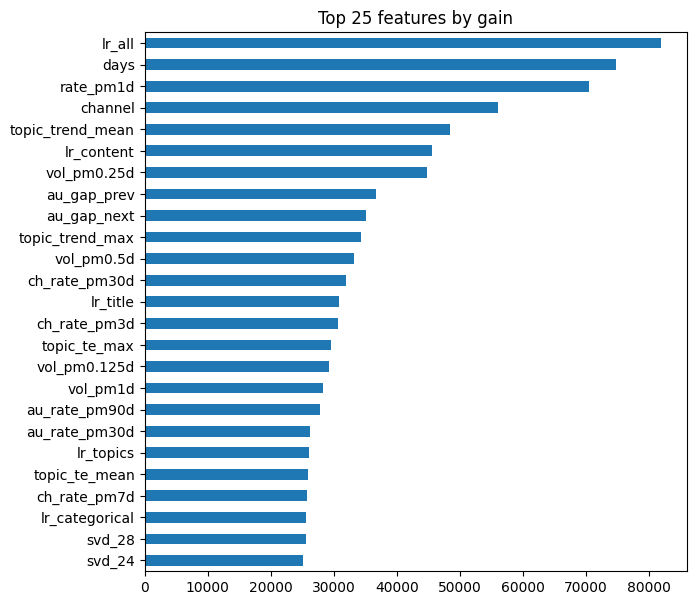

In [10]:
importance.head(25).iloc[::-1].plot.barh(figsize=(7, 7), title='Top 25 features by gain');

### 3.5 最終預測

最終預測是用全部訓練資料重新訓練的 10-seed LightGBM。

In [11]:
submission = pd.DataFrame({'Id': test['Id'], 'Popularity': lgb_pred})
submission.to_csv('submission.csv', index=False)
submission.head()

,Id,Popularity
0,27643,0.451303
1,27644,0.393566
2,27645,0.327337
3,27646,0.439389
4,27647,0.494503


## 4. 結果（5-fold CV AUC）

In [12]:
pd.Series(results, name='CV AUC').round(4).to_frame()

,CV AUC
"[text only] BoW, raw text",0.5156
"[text only] TF-IDF, raw text",0.5388
"[text only] TF-IDF, cleaned",0.5402
"[text only] TF-IDF (1,2)-gram, cleaned",0.5489
"[text only] Hashing 2^20, cleaned",0.5422
LR content,0.5529
LR title,0.5305
LR topics,0.5493
LR categorical,0.5642
LR all,0.5761


## 5. 結論

**最終模型：** 單一 LightGBM，平均 10 個 random seed，使用 metadata、時間、時間脈絡（全站、頻道、作者、主題四個層級）、topic encoding、SVD 特徵，以及 stacking 的 LR 預測值，並以固定輪數訓練。5-fold CV AUC = **0.6153**（未使用 early stopping 的誠實估計）。

| 版本 | CV AUC | Public LB |
|---|---|---|
| v1：LightGBM + stacking（early stopping） | 0.6066（偏樂觀） | 0.588 |
| v2：+ 主題 target encoding（early stopping） | 0.6083（偏樂觀，誠實估計約 0.605） | 0.587 |
| v3：+ 時間脈絡特徵（發文量、±1 天熱門率）、固定輪數、10 個 seed | 0.6136 | 0.6001 |
| v4（最終）：+ 頻道、作者、主題的時間脈絡 | **0.6153** | **0.6022** |

### 發現

1. **文章「寫了什麼」遠不如「何時、在哪裡發佈」重要。**
   * 只用文字：最好的純文字模型（清理後的 TF-IDF uni+bi-gram）AUC 只有 0.549。
   * 結構化欄位：只用頻道、作者、來源媒體、星期、時段的 one-hot（`LR categorical`），完全不看文字就有 0.564。
   * 樹模型 + metadata：LightGBM 使用 metadata、時間與 SVD 特徵，直接跳到 **0.606**。
   * 熱門程度是用社群分享數衡量的，所以它取決於發佈的情境，多於文章的用字。
2. **週末效應。** 週六、週日發佈的文章有 60–63% 熱門，平日只有 45–47%，這是最強的特徵。可能的原因是週末讀者的注意力競爭較少。
3. **頻道也有影響。**
   * 熱門率較高：`marketing`（58%）、`social-media`（56%）、`apps-software`（55%）、`lifestyle`（55%）。
   * 熱門率較低：`media`（45%）、`world`（46%）、`entertainment`（48%）。
   * 談論社群媒體本身的內容，更常在社群媒體上被分享。
4. **前處理對文字模型有幫助（與 tutorial 一致），** 但在這份資料上幅度不大（5-fold CV AUC）：

   | 文字表示法 | AUC |
   |---|---|
   | BoW，原始文字 | 0.516 |
   | TF-IDF，原始文字 | 0.539 |
   | TF-IDF，清理後（stop words + stemming） | 0.540 |
   | TF-IDF，清理後 + bi-gram | 0.549 |
   | Feature hashing（2^20），清理後 | 0.542 |

   TF-IDF 明顯勝過原始字數統計，否則長文章會主導結果。
5. **簡單的數量特徵單獨很弱，組合起來才有用。** `n_images`、`n_links`、`n_words` 單獨的 AUC 都只有 0.51 左右，但在樹模型中會和頻道、時間產生交互作用。
6. **注意力的競爭。** 同時段發佈的文章數量與熱門程度呈**負相關**：±12 小時內的發文量單獨 AUC 為 0.435，代表同時發的文章越多，每篇越不容易熱門。前後 ±1 天其他文章的熱門率也是很強的訊號（單獨 AUC 0.577），反映每天社群流量的起伏。這些時間脈絡特徵合計帶來 +0.007 AUC，是基本 metadata 之後最大的單一進步。把同樣的概念套用到頻道、作者與主題，又多了 +0.002。其中主題特別有**時效性**：一個主題在前後一週的熱門率（單獨 AUC 0.568），比它歷來的熱門率（0.546）更有預測力。
7. **對樹模型而言，主題熱門率是最好的特徵。** Out-of-fold 的主題 target encoding 統計量帶來約 +0.005 AUC。連結到其他 Mashable 文章（self-reference）沒有幫助，因為不到 2% 的連結指向訓練集中的文章。
8. **Stacking 有些微幫助**（LightGBM 從 0.6039 → 0.6062）。LR 預測值已經是特徵之後，再把 LR 拿來 blend 就沒有額外效果。
9. **調參幾乎沒有影響。** 同一個 LightGBM 從 3 個 seed 增加到 10 個 seed 有一點幫助（0.6127 → 0.6136），學習率、樹的大小、正則化的變動只造成約 ±0.001 的差異。

### 遇到的困難

* **逐欄位解析很重要。** HTML 的 byline 大約有 8 種版型，例如轉載文章會把作者以純文字放在 `<span class="byline basic">`，並另外附上 `/publishers/` 連結。太簡單的 selector 會抓不到這些文章的作者。
* **在 validation fold 上 early stopping 會讓 CV 虛高。** 讓每個 validation fold 自己決定停止輪數，分數看起來比實際好 0.003–0.004。改用固定輪數後，CV 與測試集上的表現更一致。
* **Target encoding 必須 out-of-fold。** 直接用全部訓練資料計算作者熱門率會洩漏標籤，讓 CV 虛高。Stacking 的每一層也都必須使用相同的 fold。

### 心得（Takeaways）

* **特徵比模型重要。** 加入結構化特徵（時間、頻道、作者）讓 AUC 從 0.549 提升到 0.604，時間脈絡特徵又多了 +0.009；而所有模型端的改動（seed 平均、調參）加起來只有約 +0.001。
* 最好的特徵來自思考熱門程度是**人們在某個時間點於社群媒體上分享**，而不是來自文章本身的文字。
* 一定要先建立簡單的 baseline 與 ablation 表。沒有它們，發佈時間特徵帶來的進步就不會被發現。